# Where Should a Distribution Centre Go? Network Design and Routing for Taiwan

A national online retailer has to answer two linked questions: where to put its distribution centres, and how to route its trucks from them. They are usually solved separately, and that hides a problem. The network model needs a delivery cost per kilometre before anyone has seen a route.

This notebook joins the two, using OR-Tools, on Taiwan's real geography:

1. How many distribution centres (DCs) should there be, and where?
2. How wrong is a simple per-kilometre delivery estimate, and does it change the decision?
3. What does next-morning delivery to the east coast cost, beyond the Central Mountain Range?
4. How much does route optimisation save, and how far can the solver be trusted?
5. How fragile is the chosen network if a DC is lost?

**What is real and what is assumed.** Population by township and road distances are real. The company, its volume and all its costs are assumptions, set out in the next cell. Results are comparisons between options on these assumptions, not a budget.

The optimisation runs in `scripts/run_experiments.py`, which takes about 40 minutes. This notebook reads its results.

## 1. Setup and assumptions

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Polygon

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from network_design import geography as g
from network_design import network as n
from network_design import routing as rt
from network_design import scenario as sc

FIGURES, TABLES = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)

INK, SOFT, GRID, MUTED = "#16202E", "#51606F", "#DDE3EA", "#A9B2BC"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110, "axes.edgecolor": "#C9D1D9", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.titlecolor": INK, "axes.labelcolor": SOFT, "xtick.color": SOFT, "ytick.color": SOFT,
                     "legend.frameon": False, "lines.linewidth": 2})
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 80)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")


def table_of(name):
    return pd.read_csv(TABLES / f"{name}.csv")


table, km, hours = g.load_geography()
scenario, fleet = sc.Scenario(), sc.Fleet()
truck = hours * scenario.truck_time_factor
outlines = json.loads((g.PROCESSED_DIR / "township_outlines.json").read_text(encoding="utf-8"))
networks = json.loads((g.PROCESSED_DIR / "networks.json").read_text(encoding="utf-8"))
sites = sc.candidate_sites(table)
label = {i: g.english_label(c, e) for i, (c, e) in enumerate(zip(table["county"], table["town_en"]))}

pd.Series({
    "Parcels a year": f"{scenario.parcels_per_year:,.0f}",
    "DC cost a year, at rent multiplier 1.0": f"NT${scenario.dc_fixed_cost:,.0f}",
    "Rent multiplier": "1.6 Taipei and New Taipei; 1.2 Keelung, Taoyuan, Hsinchu; 1.0 other special municipalities; 0.8 elsewhere",
    "DC capacity": f"{scenario.dc_capacity:,.0f} parcels a year",
    "Handling": f"NT${scenario.handling_per_parcel:.0f} a parcel, at every DC",
    "Linehaul from the Dayuan hub": f"NT${scenario.linehaul_per_parcel_km} a parcel-km",
    "Truck": f"{fleet.capacity:,} parcels; NT${fleet.cost_per_km:.0f}/km, NT${fleet.cost_per_hour:.0f}/hour, NT${fleet.cost_per_day:,.0f}/day",
    "Truck speed": f"road-server car times x {scenario.truck_time_factor}",
    "Service promise": f"leave at 03:00, reach each township station by 09:00, back within {fleet.shift_hours:.0f} hours",
    "Farthest station this allows": f"{fleet.max_one_way_hours:.2f} truck hours one way",
    "Operating days": "300 a year",
}, name="assumption").to_frame()

,assumption
Parcels a year,"20,000,000"
"DC cost a year, at rent multiplier 1.0","NT$60,000,000"
Rent multiplier,"1.6 Taipei and New Taipei; 1.2 Keelung, Taoyuan, Hsinchu; 1.0 other special ..."
DC capacity,"12,000,000 parcels a year"
Handling,"NT$10 a parcel, at every DC"
Linehaul from the Dayuan hub,NT$0.0133 a parcel-km
Truck,"1,500 parcels; NT$30/km, NT$350/hour, NT$2,500/day"
Truck speed,road-server car times x 1.25
Service promise,"leave at 03:00, reach each township station by 09:00, back within 10 hours"
Farthest station this allows,4.83 truck hours one way


## 2. Geography: why straight lines would be wrong

Each of the 349 mainland townships becomes one delivery station, with parcels in proportion to population. 19 offshore townships holding 1.2% of the population are excluded, because they depend on ferries and flights.

Each township needs a representative point. Using the centre of a mountain township's polygon can land in forest, so a point is taken from the village nearest the population-weighted centre. Township points far from a road are moved to a village that is both near a road and reachable at a plausible speed. Road distances and times come from OpenStreetMap through the OSRM server, saved once as a snapshot.

,value
Mainland townships,349
Population,"22,933,763"
Candidate DC sites,32
"Road / straight-line distance, median",1.28
"Road / straight-line distance, 95th percentile",2.56
"Road / straight-line distance, east to west pairs, median",2.13
Township points moved to an accessible village,13
Largest remaining distance from point to road (km),9.2


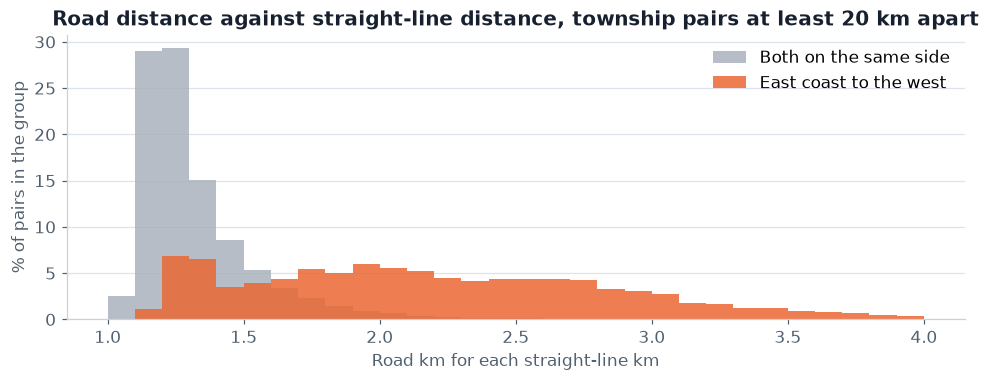

In [2]:
population = table["population"].to_numpy(dtype=float)
lat, lon = np.radians(table["lat"].to_numpy()), np.radians(table["lon"].to_numpy())
a = np.sin((lat[:, None] - lat[None, :]) / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lon[:, None] - lon[None, :]) / 2) ** 2
straight = 2 * 6371 * np.arcsin(np.sqrt(a))
pairs = np.triu_indices(len(table), 1)
ratio = km[pairs] / np.maximum(straight[pairs], 1)
far = straight[pairs] >= 20
east = table["county"].isin(["花蓮縣", "臺東縣"]).to_numpy()
crossing = east[pairs[0]] != east[pairs[1]]

profile = pd.Series({
    "Mainland townships": len(table), "Population": f"{table['population'].sum():,}", "Candidate DC sites": len(sites),
    "Road / straight-line distance, median": round(float(np.median(ratio[far])), 2),
    "Road / straight-line distance, 95th percentile": round(float(np.percentile(ratio[far], 95)), 2),
    "Road / straight-line distance, east to west pairs, median": round(float(np.median(ratio[far & crossing])), 2),
    "Township points moved to an accessible village": int(table["point_moved"].sum()),
    "Largest remaining distance from point to road (km)": round(float(table["snap_m"].max() / 1000), 1),
})
profile.rename("value").to_csv(TABLES / "geography_profile.csv", index_label="measure")
display(profile.to_frame("value"))

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(1, 4.1, 0.1)
for mask, colour, name in ((far & ~crossing, MUTED, "Both on the same side"), (far & crossing, SLOTS[1], "East coast to the west")):
    ax.hist(ratio[mask], bins=bins, weights=np.full(mask.sum(), 100 / mask.sum()), color=colour, alpha=0.85, label=name)
ax.set(title="Road distance against straight-line distance, township pairs at least 20 km apart", xlabel="Road km for each straight-line km", ylabel="% of pairs in the group")
ax.legend()
ax.grid(axis="x", visible=False)
save(fig, "01_road_vs_straight")
plt.show()

**Straight lines would mislead most exactly where it matters.** Road distance is typically 28% longer than the straight line, and about double for trips between the east coast and the west, because the only way across is around or over the mountains.

## 3. How many DCs, and where?

For each DC count, OR-Tools CP-SAT chooses sites from 32 candidates and assigns every township to one DC. The candidates follow a fixed rule: the largest township in each county or city, the next two in each special municipality, and the hub. Each model is solved to proven optimality. Every network is then costed a second way, by routing trucks on five simulated days.

,dcs,sites,status,fixed_cost,linehaul_cost,routed_delivery_cost,routed_total_cost,cost_per_parcel,trucks_per_day,population_within_2h_pct,longest_trip_hours,dropped_stops
7,3,Changhua City; Taitung City; Taoyuan District,OPTIMAL,168000000.0,25021286.5,242397297.0,635418583.5,31.8,73.6,77.7,4.8,0
8,4,Changhua City; Pingtung City; Hualien City; Taoyuan District,OPTIMAL,216000000.0,34315753.8,183691776.0,634007529.8,31.7,67.6,98.5,4.6,0
9,5,Changhua City; Pingtung City; Hualien City; Chiayi City West District; Taoyu...,OPTIMAL,264000000.0,33558679.7,173335275.0,670893954.7,33.5,66.2,98.5,4.6,0
10,6,Toufen City; Changhua City; Pingtung City; Hualien City; Chiayi City West Di...,OPTIMAL,312000000.0,34159116.9,168870786.0,715029902.9,35.8,65.8,98.5,4.6,0
11,7,Yilan City; Toufen City; Changhua City; Pingtung City; Hualien City; Chiayi ...,OPTIMAL,360000000.0,34576499.0,166270357.5,760846856.5,38.0,66.8,98.6,4.6,0
12,8,Yilan City; Toufen City; Changhua City; Pingtung City; Taitung City; Hualien...,OPTIMAL,408000000.0,35188177.6,151398781.5,794586959.2,39.7,64.6,99.5,3.0,0
13,9,Yilan City; Toufen City; Changhua City; Douliu City; Pingtung City; Taitung ...,OPTIMAL,456000000.0,35454697.1,150128434.5,841583131.6,42.1,65.0,99.5,3.0,0


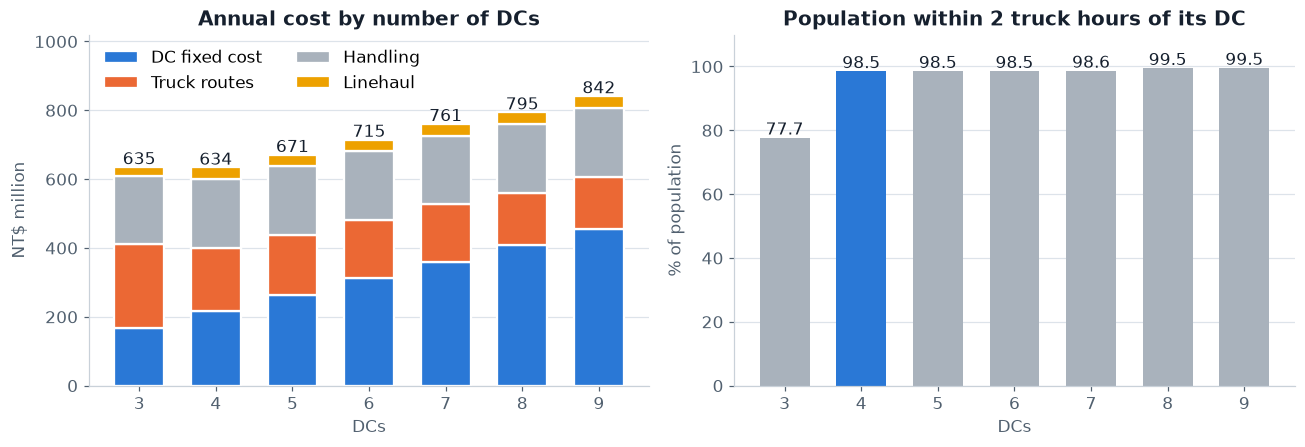

In [3]:
frontier = table_of("network_frontier")
calibrated = frontier[frontier["scenario"] == "Calibrated"].copy()
calibrated["cost_per_parcel"] = calibrated["routed_total_cost"] / scenario.parcels_per_year
view = calibrated[["dcs", "sites", "status", "fixed_cost", "linehaul_cost", "routed_delivery_cost", "routed_total_cost", "cost_per_parcel", "trucks_per_day", "population_within_2h_pct", "longest_trip_hours", "dropped_stops"]]
display(view.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
parts = [("fixed_cost", "DC fixed cost", SLOTS[0]), ("routed_delivery_cost", "Truck routes", SLOTS[1]), ("handling_cost", "Handling", MUTED), ("linehaul_cost", "Linehaul", SLOTS[3])]
bottom = np.zeros(len(calibrated))
for column, name, colour in parts:
    values = calibrated[column].to_numpy() / 1e6
    axes[0].bar(calibrated["dcs"], values, bottom=bottom, color=colour, width=0.65, label=name, edgecolor="white", linewidth=1.5)
    bottom += values
for x, total in zip(calibrated["dcs"], bottom):
    axes[0].text(x, total + 8, f"{total:.0f}", ha="center", color=INK)
axes[0].set(title="Annual cost by number of DCs", xlabel="DCs", ylabel="NT$ million", ylim=(0, 1020))
axes[0].legend(ncol=2, loc="upper left")
axes[0].grid(axis="x", visible=False)
axes[1].bar(calibrated["dcs"], calibrated["population_within_2h_pct"], color=[SLOTS[0] if d == 4 else MUTED for d in calibrated["dcs"]], width=0.65)
for x, value in zip(calibrated["dcs"], calibrated["population_within_2h_pct"]):
    axes[1].text(x, value + 1, f"{value:.1f}", ha="center", color=INK)
axes[1].set(title="Population within 2 truck hours of its DC", xlabel="DCs", ylabel="% of population", ylim=(0, 110))
axes[1].grid(axis="x", visible=False)
save(fig, "02_cost_and_service_by_dcs")
plt.show()

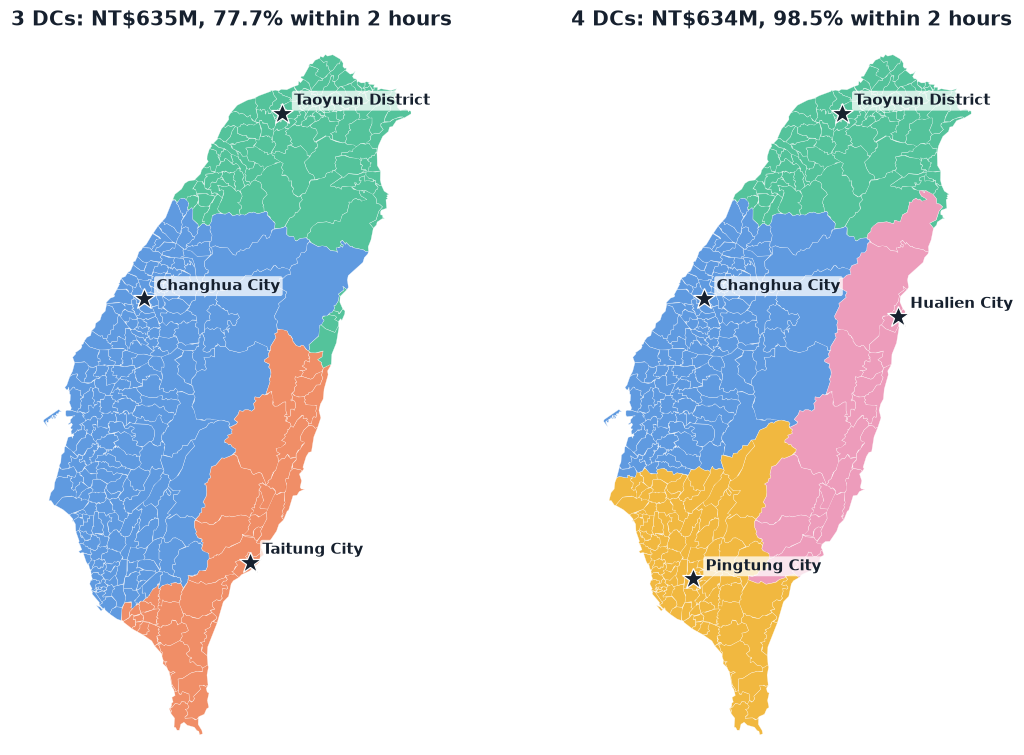

In [4]:
# A DC keeps its colour on every map, whichever other DCs are open.
site_order = list(dict.fromkeys(site for count in range(3, 9) for site in networks["networks"][str(count)]["sites"]))
site_colour = {site: SLOTS[i] for i, site in enumerate(site_order)}


def draw_map(ax, assignment, open_sites, names=None):
    for index, code in enumerate(table["town_code"]):
        colour = site_colour[int(assignment[index])]
        for ring in outlines[code]:
            ax.add_patch(Polygon(ring, closed=True, facecolor=colour, edgecolor="white", linewidth=0.25, alpha=0.75))
    for s in open_sites:
        ax.plot(table["lon"].iloc[s], table["lat"].iloc[s], marker="*", markersize=15, color=INK, markeredgecolor="white", markeredgewidth=0.8, zorder=5)
        if names:
            ax.annotate(label[s], (table["lon"].iloc[s], table["lat"].iloc[s]), xytext=names[s], textcoords="offset points", fontsize=10, color=INK, fontweight="bold", bbox=dict(boxstyle="round,pad=0.15", facecolor="white", alpha=0.75, edgecolor="none"))
    ax.set(xlim=(119.95, 122.1), ylim=(21.85, 25.4))
    ax.set_aspect(1 / np.cos(np.radians(23.7)))
    ax.axis("off")


three, four = networks["networks"]["3"], networks["networks"]["4"]
fig, axes = plt.subplots(1, 2, figsize=(11, 7))
draw_map(axes[0], np.array(three["assignment"]), three["sites"], {s: (8, 6) for s in three["sites"]})
axes[0].set_title("3 DCs: NT$635M, 77.7% within 2 hours")
draw_map(axes[1], np.array(four["assignment"]), four["sites"], {s: (8, 6) for s in four["sites"]})
axes[1].set_title("4 DCs: NT$634M, 98.5% within 2 hours")
save(fig, "03_network_maps")
plt.show()

**Three and four DCs cost the same, so service decides.** The two are 0.2% apart, too close for this model to separate. Four DCs bring 98.5% of the population within two truck hours, against 77.7% with three, because a DC at Pingtung removes the long drive from Changhua to southern Taiwan. Beyond four, each extra DC adds NT$34–47M a year, as fixed cost outweighs what it saves on trucks.

The recommended network is **Taoyuan, Changhua, Pingtung and Hualien**, at about NT$634M a year or NT$31.7 a parcel.

The site choice matters too. These are networks a planner might propose, costed on the same five days. Each needed a Hualien DC added to meet the delivery promise.

In [5]:
alternatives = table_of("alternative_networks")
optimised = alternatives.loc[alternatives["network"] == "Optimised", "routed_total_cost"].iloc[0]
alternatives["extra_vs_optimised_pct"] = (alternatives["routed_total_cost"] / optimised - 1) * 100
alternatives["extra_vs_optimised"] = alternatives["routed_total_cost"] - optimised
alternatives.round(1).to_csv(TABLES / "alternative_networks.csv", index=False)
alternatives[["network", "dcs", "sites", "fixed_cost", "routed_total_cost", "extra_vs_optimised", "extra_vs_optimised_pct"]].round(1)

,network,dcs,sites,fixed_cost,routed_total_cost,extra_vs_optimised,extra_vs_optimised_pct
0,Optimised,4,Changhua City; Pingtung City; Hualien City; Taoyuan District,216000000.0,633699473.0,0.0,0.0
1,North + south,3,Hualien City; Fengshan District; Taoyuan District,180000000.0,655763153.0,22063680.0,3.5
2,North + centre + south,4,Hualien City; Fengshan District; Xitun District; Taoyuan District,240000000.0,655923660.0,22224187.0,3.5
3,Rule: largest metros,4,Hualien City; Sanmin District; Banqiao District; Beitun District,264000000.0,681939149.0,48239676.0,7.6


**Intuitive networks cost NT$22–48M a year more.** The obvious sites sit in big cities with higher assumed rents. Changhua and Pingtung are close enough to the same customers for much less. That depends on the rent assumption, which section 8 tests.

## 4. How wrong is a per-kilometre delivery estimate?

A network model has to price delivery before routes exist. I started with NT$0.05 per parcel-km, worked out from truck cost per kilometre and load. Routing trucks gives a way to check it. A regression of each DC's daily route cost on its parcel-kilometres and stops gives a new rate, and the model is solved again until the rate settles.

,round,rate_used,rate_per_parcel_km,cost_per_stop_day,r2,mape_pct,dropped_stops
0,1,0.050,0.068,1140.403,0.899,23.390,0
1,2,0.068,0.076,1086.650,0.882,23.377,0
2,3,0.076,0.073,1110.947,0.877,21.629,0
3,4,0.073,0.078,1080.606,0.886,22.182,0


,first_estimate_model,calibrated_model,routed_trucks,routed_vs_first_estimate
dcs,,,,
3,64.0,99.2,242.4,3.8
4,36.2,56.1,183.7,5.1
5,45.4,50.9,173.3,3.8
6,41.9,47.5,168.9,4.0
7,40.9,45.0,166.3,4.1
8,40.1,43.2,151.4,3.8
9,39.6,42.0,150.1,3.8


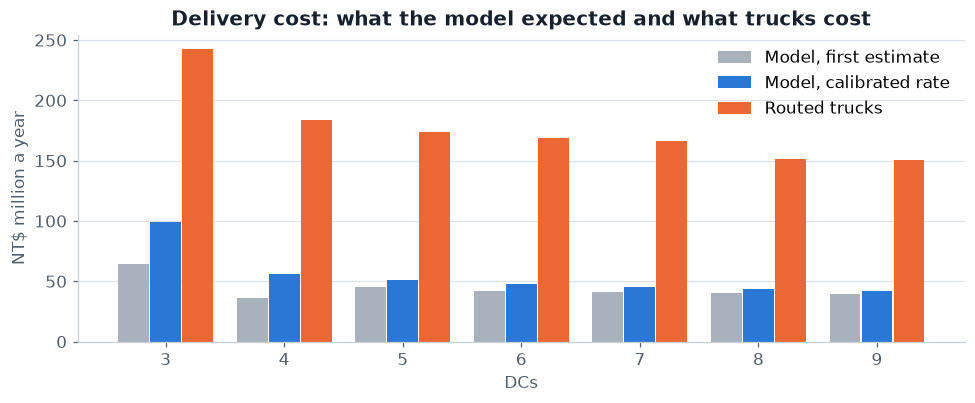

First estimate chose 3 DCs, routed cost NT$638.2M; best is 4 DCs, NT$634.0M


In [6]:
history = table_of("calibration_history")
display(history.round(3))
first = frontier[frontier["scenario"] == "First estimate"].set_index("dcs")
after = frontier[frontier["scenario"] == "Calibrated"].set_index("dcs")
gap = pd.DataFrame({"first_estimate_model": first["model_delivery_cost"], "calibrated_model": after["model_delivery_cost"], "routed_trucks": after["routed_delivery_cost"]}) / 1e6
gap["routed_vs_first_estimate"] = gap["routed_trucks"] / gap["first_estimate_model"]
gap.round(1).to_csv(TABLES / "delivery_estimate_gap.csv")
display(gap.round(1))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(gap))
ax.bar(x - 0.27, gap["first_estimate_model"], width=0.26, color=MUTED, label="Model, first estimate")
ax.bar(x, gap["calibrated_model"], width=0.26, color=SLOTS[0], label="Model, calibrated rate")
ax.bar(x + 0.27, gap["routed_trucks"], width=0.26, color=SLOTS[1], label="Routed trucks")
ax.set_xticks(x, gap.index)
ax.set(title="Delivery cost: what the model expected and what trucks cost", xlabel="DCs", ylabel="NT$ million a year")
ax.legend()
ax.grid(axis="x", visible=False)
save(fig, "04_delivery_estimate_gap")
plt.show()

first_pick = networks["first_estimate_pick"]
print(f"First estimate chose {first_pick['chosen_by_first_estimate_dcs']} DCs, routed cost NT${first_pick['routed_total_cost'] / 1e6:.1f}M; best is {first_pick['best_dcs']} DCs, NT${first_pick['best_routed_total_cost'] / 1e6:.1f}M")

**The estimate was badly wrong on the budget, and barely wrong on the decision.** At four DCs my first estimate gave NT$36M a year of delivery cost, and routed trucks cost NT$184M, five times as much. Calibration raises the rate to about NT$0.08, yet most of the gap remains, because much of a route's cost comes from stopping at each station whichever DC serves it: about NT$1,080 a station a day in the fit, or NT$113M a year. That part cannot change the network choice.

The decision moved far less. The first estimate preferred three DCs and costs 0.7% more than the best network. So the honest finding is that a rough estimate would have chosen a reasonable network but would have understated the delivery budget several times over. Calibration improves the rate, but the fit is rough: R² is about 0.89 and typical error is about 22%.

## 5. The east coast

The promise of next-morning delivery forces a DC east of the mountains, in every network and every sensitivity case tested. So what does it cost?

,dc,townships,population_share_pct,parcels_per_year,utilisation_pct,fixed_per_parcel,linehaul_per_parcel,routes_per_parcel,total_per_parcel
3,Taoyuan District,98,48.2,9638938.9,80.3,7.5,0.2,5.6,23.3
0,Changhua City,127,27.6,5514963.2,46.0,8.7,2.0,9.9,30.6
1,Pingtung City,100,22.1,4417217.5,36.8,10.9,4.5,10.3,35.7
2,Hualien City,24,2.1,428880.3,3.6,111.9,2.6,69.1,193.6


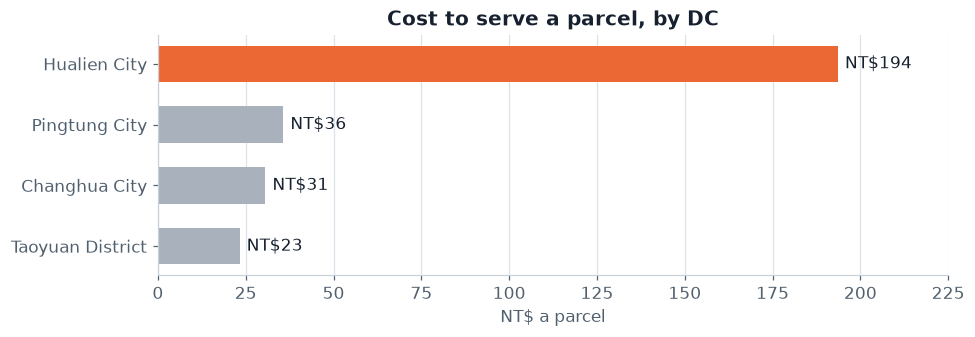

,max_truck_hours,feasible_without_east_dc,total_model_cost,dcs
0,4.8,False,NaN,NaN
1,5.5,False,NaN,NaN
2,6.0,True,475319509.1,3.0
3,7.0,True,461773511.3,2.0
4,8.0,True,448581469.8,2.0


,value
east_population_share_pct,2.22
east_parcels_per_year,443454.48
in_house_total_cost,633699473.29
west_only_dcs,2
west_only_sites,Chiayi City West District; Taoyuan District
west_only_total_cost,533994619.87
west_only_dropped_stops,0
saving_before_carrier_fees,99704853.43
break_even_carrier_price_per_parcel,224.84


{'population_within_1h_pct': 51.5, 'population_within_2h_pct': 91.5, 'population_within_3h_pct': 99.7, 'population_within_4h_pct': 99.9, 'longest_trip_hours': 4.2, 'population_weighted_hours': 1.1}


In [7]:
serve = table_of("cost_to_serve_by_dc").sort_values("total_per_parcel")
display(serve.round(1))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(serve["dc"], serve["total_per_parcel"], color=[SLOTS[1] if "Hualien" in d else MUTED for d in serve["dc"]], height=0.6)
for y, value in enumerate(serve["total_per_parcel"]):
    ax.text(value + 2, y, f"NT${value:.0f}", va="center", color=INK)
ax.set(title="Cost to serve a parcel, by DC", xlabel="NT$ a parcel", xlim=(0, 225))
ax.grid(axis="y", visible=False)
save(fig, "05_cost_to_serve")
plt.show()

without = table_of("east_coast_without_dc")
display(without.round(1))
outsourcing = table_of("east_coast_outsourcing").iloc[0]
display(outsourcing.to_frame("value"))

keep = np.flatnonzero(~east)
west = table.iloc[keep].reset_index(drop=True)
west_scenario = scenario.scaled(parcels_per_year=float(sc.yearly_parcels(population, scenario)[keep].sum()), delivery_per_parcel_km=networks["rate"])
west_sites = sc.candidate_sites(west)
west_network = n.solve_network(west, km[np.ix_(keep, keep)], hours[np.ix_(keep, keep)], west_scenario, west_sites, n_open=2, max_hours=fleet.max_one_way_hours, time_limit=60)
west_service = n.service_levels(west, hours[np.ix_(keep, keep)], west_network.assignment, west_scenario)
print({k: round(v, 1) for k, v in west_service.items()})

**2.2% of parcels account for about 16% of network cost.** The Hualien DC costs NT$194 a parcel, against NT$23–36 in the west, because it spreads a whole DC over very few parcels and its trucks run long routes. Without an east coast DC, the promise cannot be met until the one-way limit reaches six truck hours, which a ten-hour shift does not allow.

Handing Hualien and Taitung to a carrier gives a clear break-even. The network then needs only two western DCs and costs about NT$100M a year less. **A carrier charging under about NT$225 a parcel would be cheaper than running the east in-house.** There are two conditions. The two-DC western network is weaker on service, with 91.5% of the western population within two truck hours against 98.5% nationally under the recommended network. And the carrier must keep the same promise. The company should obtain real quotes, and compare a western network of three DCs if the two-hour service matters.

## 6. Route optimisation

Here each DC's daily routes are solved three ways on five simulated days, using the chosen network.

,method,cost,km,hours,trucks,dropped,rule_breaks,saving_vs_nearest_pct,annual_saving_vs_nearest
0,Nearest neighbour,716667.5,13156.6,441.3,67.0,0.0,0.0,0.0,0.0
1,Savings + guided local search,606027.5,10233.6,384.3,65.8,0.0,0.0,15.4,33191989.5
2,Savings + local search,606019.9,10235.2,384.2,65.8,0.0,0.0,15.4,33194263.5


,seconds,cost,trucks,dc,stops
0,1,185690.0,19,Changhua City,127
1,2,183730.0,19,Changhua City,127
2,5,181247.0,19,Changhua City,127
3,10,179737.0,18,Changhua City,127
4,30,178438.0,18,Changhua City,127
5,60,178427.0,18,Changhua City,127


,instance,customers,best_known,seconds,found,gap_pct
0,A-n32-k5,31,784,5,784,0.00
1,A-n32-k5,31,784,30,784,0.00
2,B-n31-k5,30,672,5,686,2.08
3,B-n31-k5,30,672,30,675,0.45
4,M-n101-k10,100,820,5,831,1.34
5,M-n101-k10,100,820,30,831,1.34
6,X-n101-k25,100,27591,5,29419,6.63
7,X-n101-k25,100,27591,30,29087,5.42


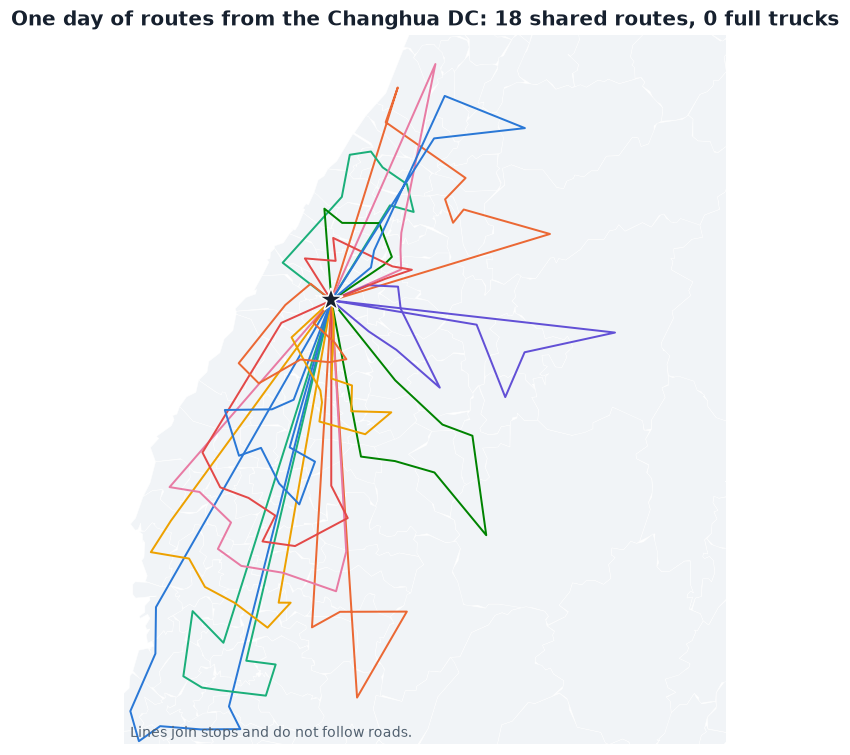

In [8]:
methods = table_of("routing_methods")
display(methods.round(1))
convergence = table_of("routing_convergence")
display(convergence.round(0))
benchmarks = table_of("solver_benchmarks")
display(benchmarks)

depot = four["sites"][[table["town"].iloc[s] for s in four["sites"]].index("彰化市")]
served = np.flatnonzero(np.array(four["assignment"]) == depot).tolist()
day = rt.daily_demand(sc.yearly_parcels(population, scenario), np.random.default_rng(5), 300)[served]
plan = rt.solve_routes(depot, served, day, km, truck, fleet, time_limit=10)
assert rt.check_plan(plan, depot, served, day, km, truck, fleet) == []

fig, ax = plt.subplots(figsize=(7, 7))
for code in table["town_code"]:
    for ring in outlines[code]:
        ax.add_patch(Polygon(ring, closed=True, facecolor="#F1F4F7", edgecolor="white", linewidth=0.3))
for i, route in enumerate(plan.routes):
    path = [depot] + route + [depot]
    ax.plot(table["lon"].iloc[path], table["lat"].iloc[path], color=SLOTS[i % 8], linewidth=1.3)
ax.plot(table["lon"].iloc[depot], table["lat"].iloc[depot], marker="*", markersize=16, color=INK, markeredgecolor="white")
ax.set(xlim=(120.1, 121.4), ylim=(23.2, 24.6), title=f"One day of routes from the Changhua DC: {len(plan.routes)} shared routes, {plan.dedicated_trips} full trucks")
ax.set_aspect(1 / np.cos(np.radians(23.9)))
ax.axis("off")
ax.text(0.01, 0.01, "Lines join stops and do not follow roads.", transform=ax.transAxes, color=SOFT, fontsize=9)
save(fig, "06_route_example")
plt.show()

**Good routing saves 15% against a planner's rule of thumb, worth about NT$33M a year,** comparable with the choice of sites. All of it comes from the savings construction with local search: guided local search, limited to 15 seconds for each DC, found nothing further. Search time does matter up to a point. On the largest DC, with 127 stations, cost falls about 4% between 1 and 30 seconds, and then stops improving.

**The solver is strong, but not proven optimal.** On public benchmarks it reaches the known optimum on one instance and comes within 0.5% and 1.3% on two others, but stays 5.4% above the best known solution on the X-n101-k25 instance after 30 seconds. So route costs here are good solutions, not guaranteed best ones, unlike the network model, which is solved to proven optimality.

## 7. What if a DC is lost?

In [9]:
resilience = table_of("resilience_one_dc_lost")
resilience.round(1)

,lost_dc,meets_time_limit,capacity_ok,extra_transport_cost_pct,population_beyond_limit_pct,longest_trip_hours,busiest_dc_utilisation_pct
0,Changhua City,True,True,52.3,0.0,4.8,100.0
1,Pingtung City,False,True,36.4,0.2,5.7,82.6
2,Hualien City,False,True,4.1,0.5,6.6,82.4
3,Taoyuan District,False,True,118.2,0.0,4.9,96.6


**The network survives the loss of any one DC on capacity, but not comfortably.** Losing Taoyuan more than doubles transport cost and leaves another DC at 97% of capacity, and losing Changhua pushes a DC to 100%. Losing Pingtung or Hualien breaks the delivery promise for a small share of people, with trips of up to 7.2 hours. Taoyuan serves 48% of the population and runs at 80% of capacity, so it is the place to plan a backup.

## 8. Do the conclusions depend on the assumptions?

Each case recalibrates the delivery rate and reruns the choice of network.

In [10]:
sensitivity = table_of("sensitivity")
sensitivity[["case", "rate_per_parcel_km", "best_dcs", "sites", "routed_total_cost", "cost_per_parcel", "next_best_gap_pct", "dropped_stops"]].round(3)

,case,rate_per_parcel_km,best_dcs,sites,routed_total_cost,cost_per_parcel,next_best_gap_pct,dropped_stops
0,Demand 10M parcels,0.060,3,Toufen City; Pingtung City; Hualien City,4.652691e+08,46.527,4.909,0
1,Demand 40M parcels,0.069,4,Changhua City; Pingtung City; Hualien City; Taoyuan District,9.237052e+08,23.093,0.952,0
2,DC cost +30%,0.054,3,Toufen City; Taitung City; Chiayi City West District,6.546409e+08,32.732,5.976,0
3,DC cost -30%,0.079,4,Changhua City; Pingtung City; Hualien City; Taoyuan District,5.697709e+08,28.489,2.478,0
4,Flat rent,0.073,3,Changhua City; Taitung City; Xinzhuang District,6.391684e+08,31.958,2.949,0
5,Fuel and transport +30%,0.088,4,Changhua City; Pingtung City; Hualien City; Taoyuan District,6.707620e+08,33.538,2.153,0
6,"Smaller trucks (1,000 parcels)",0.107,4,Changhua City; Pingtung City; Hualien City; Taoyuan District,6.569002e+08,32.845,0.235,0
7,Later deadline (10:00),0.086,3,Hualien City; Chiayi City West District; Taoyuan District,6.109995e+08,30.550,0.668,0


**The shape holds, and the exact sites do not.**

- **Three or four DCs in all eight cases**, with one east of the mountains every time.
- **Scale matters a lot.** A parcel costs about NT$47 at 10 million parcels a year, NT$32 at 20 million and NT$23 at 40 million.
- **The precise sites move.** Four cases keep the recommended network, and the rest choose different three-DC networks, often within a few percent of the next option. The cost surface is flat, so a real decision should rest on real rent quotes and site availability rather than on the small differences found here.

## 9. What this means for decisions

| Finding | Decision it informs |
|---|---|
| Three and four DCs cost the same, while four give far better service | Choose four: Taoyuan, Changhua, Pingtung, Hualien. Decide on service, because cost cannot separate them |
| Intuitive big-city networks cost NT$22–48M more | Look at sites just outside the big cities, subject to real rent quotes |
| A per-kilometre estimate understated the delivery budget up to five times | Check a network model against routed trucks before setting a budget |
| 2.2% of parcels drive about 16% of cost | Get carrier quotes for the east coast, against a break-even of about NT$225 a parcel |
| Good routing saves about 15% against a rule of thumb | Adopt routing software first: standard methods deliver the gain within seconds to a minute |
| Taoyuan carries 48% of the population | Plan a backup for Taoyuan before the other DCs |

## 10. Limitations

- **The company is fictional.** Volumes, rents, fleet costs and the service promise are assumptions, not quotes. Comparisons are more reliable than amounts.
- **Demand follows population.** Real demand also follows income, age and urban density. There are no parcel data here.
- **One point per township.** A station stands for a whole township, and delivery beyond the station is not modelled. Two mountain township points remain far from a road: Zhuoxi (9.2 km) and Xiulin (2.6 km).
- **Road data.** Times are for cars from OpenStreetMap, scaled by an assumed factor, with no traffic, weather or closures, which matter on the Suhua Highway and mountain roads. The server's data are a snapshot.
- **Fixed candidates.** The 32 candidates follow a rule, and do not reflect available land or zoning, so a better site may exist outside the list.
- **Routes are good, not proven best.** The route costs are heuristic solutions on five simulated days, so differences under about 1% should not be read as real.
- **One period.** DC capacity is a fixed limit, with no seasonal peaks or growth over time.